# 2 · Python and neural network foundations

**Question.** What changes when a regression model learns its own nonlinear features?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/02-python-neural-networks.ipynb) · [Python setup](https://chikuang.github.io/teaching/genai/python-workflow.html)

**Python support:** [Appendix A](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html) explains syntax, shapes, classes, gradients, and validation in small executable steps. Use the page’s **Show all code** control while working through the lab.

A neural network is a parameterized function fitted by an optimization procedure. Its hidden layers are learned basis expansions. This chapter starts with array operations, connects logistic regression to a small network, and makes the training loop visible. We will compare both models on the same simulated classification problem, using a validation set to select a checkpoint and a separate test set for final evaluation.

**Prerequisites:** Chapter 1, matrix multiplication, likelihood, and differentiation. **Outcomes:** read tensor shapes; check a gradient; implement minibatch training; distinguish optimization error from generalization error. All cells run on a CPU using NumPy, Matplotlib, and PyTorch. Run them in order.

## Pipeline and framework

![Training minibatches produce optimizer updates; validation selects a checkpoint, and a separate test set evaluates the frozen model. Remember: train to learn, validate to choose, test once to report.](https://chikuang.github.io/teaching/genai/_static/diagrams/02-neural-training.png)

The **inner loop** updates parameters using training minibatches. The **outer selection loop** compares checkpoints on validation data. The test set belongs to neither loop. This distinction matters even for the small network below: looking repeatedly at test loss and changing the model would turn that sample into development data.

| Step | Input and output | What to inspect |
|:--|:--|:--|
| Prepare | Raw observations become tensors and fixed split indices. | Feature shape, label shape, class proportions, and preprocessing fit only on training data. |
| Optimize | A minibatch and current weights produce loss, gradients, and new weights. | Clear old gradients; check finite loss and nonzero gradients where expected. |
| Select | Validation losses identify one saved checkpoint. | Save a copy of the weights; a reference to changing weights is not a checkpoint. |
| Evaluate | Frozen weights and held-out tensors produce predictions and losses. | Compare the constant predictor, logistic model, and neural network on the same observations. |

The training loop in Section 2.5 implements these steps in the order `zero_grad -> forward -> loss -> backward -> step`. Evaluation mode and disabled gradient recording serve different purposes: the former changes layers such as dropout; the latter avoids building a gradient graph. Neither substitutes for holding out observations.

## 2.1 · Arrays, shapes, and broadcasting

A NumPy array has a shape and a data type. A matrix of $n$ observations with $p$ features has shape `(n, p)`. In Python, `*` multiplies entries; `@` performs matrix multiplication. Broadcasting permits operations between compatible shapes by aligning dimensions from the right. A singleton dimension can be repeated without explicitly making copies.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(2026)
rng = np.random.default_rng(2026)
X_demo = np.array([[1., 2.], [3., 4.], [5., 6.]])
w_demo = np.array([0.5, -0.25])
print('X:', X_demo.shape, 'w:', w_demo.shape)
print('Linear predictions:', X_demo @ w_demo)
print('Column centering:', X_demo - X_demo.mean(axis=0))
print('Keep a column dimension:', X_demo[:, :1].shape)

X: (3, 2) w: (2,)
Linear predictions: [0.  0.5 1. ]
Column centering: [[-2. -2.]
 [ 0.  0.]
 [ 2.  2.]]
Keep a column dimension: (3, 1)


`X_demo[:, 0]` has shape `(3,)`, whereas `X_demo[:, :1]` has shape `(3, 1)`. This difference matters: subtracting `(n, 1)` from `(n,)` produces an `(n, n)` array, not the vector of residuals you intended. Before fitting anything, print the shapes of predictors, labels, and predictions. Use assertions when a silent broadcast could change the estimand.

A function packages a calculation with named inputs and a returned result. A class packages state and behavior. PyTorch's `nn.Module` is the base class for models; its registered parameters are the quantities an optimizer can update. A tensor resembles an array but can also participate in automatic differentiation.

> **Example 2.1 · A shape error can produce a plausible number**
>
> **Setup.** Two predicted probabilities are stored as `[[0.2], [0.8]]`, with shape `(2, 1)`. Their labels are `[0, 1]`, with shape `(2,)`.
>
> **Work it through.** Subtraction broadcasts the labels across both rows and returns `[[0.2, -0.8], [0.8, -0.2]]`, a `(2, 2)` array. Averaging its squared entries gives $0.34$. Reshaping the labels to `(2, 1)` instead gives the intended residuals `[[0.2], [-0.2]]` and mean square $0.04$.
>
> **What this shows.** The incorrect operation runs successfully and returns a finite loss. It compares each prediction with both labels instead of its own label. Check dimensions and observation alignment before trusting a training curve; a falling loss cannot certify that the intended problem was implemented.

## 2.2 · From logistic regression to learned features

For binary $Y$, write

$$
\eta_i=x_i^\top w+b,\qquad p_i=\sigma(\eta_i),\qquad
\sigma(u)=\frac{1}{1+e^{-u}}.
$$

The mean negative log likelihood is

$$
L(w,b)=\frac1n\sum_i\{\log(1+e^{\eta_i})-y_i\eta_i\}.
$$

The gradient of Equation [(2.1)](https://chikuang.github.io/teaching/genai/chapters/02-python-neural-networks.html#equation-eq-logistic-loss) in $w$ is $X^\top(p-y)/n$. A hidden layer replaces the fixed features with $h(x)=\tanh(W_1x+b_1)$ and uses $\eta=w_2^\top h(x)+b_2$. Both layers are estimated jointly. The resulting likelihood is familiar; the feature map and nonconvex optimization are the new parts. A deeper model does not remove the need for a sampling model, a baseline, or independent evaluation.

We use `BCEWithLogitsLoss`, which accepts logits and implements a stable binary cross-entropy. Do **not** apply a sigmoid before passing predictions to this loss. Apply it when you need probabilities for interpretation.

### Forward and backward passes with dimensions

For a minibatch of $m$ rows, let $X\in\mathbb R^{m\times p}$, $W_1\in\mathbb R^{p\times h}$, $b_1,w_2\in\mathbb R^h$, and $b_2\in\mathbb R$. The column-vector formula above becomes

$$
A=XW_1+\mathbf1_m b_1^\top,\quad H=\tanh(A),\quad
\eta=Hw_2+b_2\mathbf1_m,\quad \pi=\sigma(\eta).
$$

Here $\pi\in(0,1)^m$ is the vector of predicted probabilities and $p$ counts input features. Differentiating the forward map in Equation [(2.2)](https://chikuang.github.io/teaching/genai/chapters/02-python-neural-networks.html#equation-eq-neural-forward) with $\delta=(\pi-y)/m$, the chain rule gives the **unregularized minibatch-loss** gradients

$$
\begin{aligned}
\nabla_{w_2}L&=H^\top\delta,&\quad \partial L/\partial b_2&=\mathbf1_m^\top\delta,\\
G&=(\delta w_2^\top)\odot(1-H\odot H),& \nabla_{W_1}L&=X^\top G,\\
\nabla_{b_1}L&=G^\top\mathbf1_m.&&
\end{aligned}
$$

$\odot$ multiplies entries, and $G$ has shape $m\times h$. The derivative $1-\tanh^2(A)$ in Equation [(2.3)](https://chikuang.github.io/teaching/genai/chapters/02-python-neural-networks.html#equation-eq-backprop) explains how a saturated hidden unit can transmit a small gradient. `nn.Linear(p, h)` stores the transpose of our $W_1$, with shape `(h, p)`; its forward calculation still implements this map. In the experiment $p=2$ and $h=16$.

> **Example 2.2 · One gradient step by hand**
>
> **Setup.** Use one observation $x=2$, $y=1$, a scalar weight $w$, and no intercept. Start at $w=0$, with learning rate $0.1$.
>
> **Work it through.** The logit is $xw=0$ and the probability is $p=0.5$. Equation [(2.1)](https://chikuang.github.io/teaching/genai/chapters/02-python-neural-networks.html#equation-eq-logistic-loss) gives loss $\log 2\approx0.6931$ and derivative $x(p-y)=2(-0.5)=-1$. Gradient descent sets $w_{\mathrm{new}}=0-0.1(-1)=0.1$. The new probability is $\sigma(0.2)\approx0.5498$, with loss $\log(1+e^{-0.2})\approx0.5981$.
>
> **What this shows.** The negative derivative increases the weight, making the observed positive outcome more probable. This tiny calculation provides a known answer for checking automatic differentiation, update signs, and loss reduction before training a larger network.

## 2.3 · Check automatic differentiation on a known answer

Autodiff applies the chain rule to a recorded computation graph. It is not numerical differentiation. A finite-difference check is nevertheless useful for catching mistakes in your formula or tensor indexing.

In [2]:
x_check = torch.tensor(X_demo, dtype=torch.float64)
y_check = torch.tensor([0., 1., 1.], dtype=torch.float64)
w = torch.tensor([0.2, -0.1], dtype=torch.float64, requires_grad=True)
loss = nn.functional.binary_cross_entropy_with_logits(x_check @ w, y_check)
loss.backward()
autodiff = w.grad.detach().numpy().copy()
manual = (x_check.T @ (torch.sigmoid(x_check @ w) - y_check) / 3).detach().numpy()

def objective(v):
    z = X_demo @ v
    return np.mean(np.logaddexp(0, z) - y_check.numpy() * z)

h = 1e-5
base = w.detach().numpy()
finite_difference = np.array([
    (objective(base + h * e) - objective(base - h * e)) / (2 * h)
    for e in np.eye(2)
])
print('Autodiff:', autodiff)
print('Analytic:', manual)
print('Finite difference:', finite_difference)
assert np.allclose(autodiff, manual, atol=1e-10)
assert np.allclose(autodiff, finite_difference, atol=1e-8)

Autodiff: [-0.95235324 -1.06951268]
Analytic: [-0.95235324 -1.06951268]
Finite difference: [-0.95235324 -1.06951268]


Gradients accumulate in `.grad`. An optimizer therefore needs `zero_grad()` before a new backward pass. `detach()` stops tracking a tensor for differentiation; it does not change its numerical value. Use `torch.no_grad()` for evaluation to avoid building an unnecessary graph.

## 2.4 · Simulate a nonlinear problem and split first

The true log odds below depend on squared radius. A linear decision boundary is misspecified. This is deliberate: we want an example in which nonlinear features have a reason to help, rather than a contest in which model complexity is rewarded without explanation.

In [3]:
X = rng.normal(size=(1200, 2)).astype('float32')
true_logits = 2.5 * (1.5 - (X ** 2).sum(axis=1))
true_p = 1 / (1 + np.exp(-true_logits))
y = rng.binomial(1, true_p).astype('float32')
order = rng.permutation(len(y))
train, valid, test = order[:700], order[700:950], order[950:]
mean = X[train].mean(axis=0)
scale = X[train].std(axis=0)
Z = torch.tensor((X - mean) / scale)
y_tensor = torch.tensor(y)
print('Train / validation / test:', len(train), len(valid), len(test))
print('Training class proportion:', round(float(y[train].mean()), 3))

Train / validation / test: 700 250 250
Training class proportion: 0.491


Estimate preprocessing parameters on training observations only. Validation observations influence model selection, so they are not a final test sample. The simulation's true probabilities are available for understanding the example; we do not feed them into the optimizer.

## 2.5 · A training loop you can inspect

One epoch visits all training observations. A minibatch supplies a noisy gradient estimate. We shuffle the training indices each epoch, evaluate validation loss without gradients, and save the parameters with the lowest validation loss. `state_dict()` contains model parameters; copying its tensors prevents later training from changing the saved checkpoint.

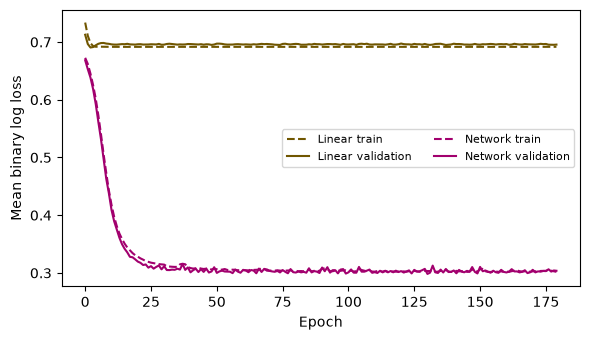

In [4]:
import copy

def fit(model, epochs=180, features=Z):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.02, weight_decay=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    history, best_loss, best_state = [], float('inf'), None
    local_rng = np.random.default_rng(90)
    for epoch in range(epochs):
        model.train()
        for batch in np.array_split(local_rng.permutation(train), 7):
            optimizer.zero_grad()
            logits = model(features[batch]).squeeze(-1)
            loss = loss_fn(logits, y_tensor[batch])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(features[train]).squeeze(-1), y_tensor[train]).item()
            valid_loss = loss_fn(model(features[valid]).squeeze(-1), y_tensor[valid]).item()
        history.append((train_loss, valid_loss))
        if valid_loss < best_loss:
            best_loss = valid_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, np.asarray(history)

linear, linear_curve = fit(nn.Linear(2, 1))
network, network_curve = fit(nn.Sequential(
    nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 1)
))
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, curve, color in [('Linear', linear_curve, '#705600'),
                            ('Network', network_curve, '#a2006e')]:
    ax.plot(curve[:, 0], '--', color=color, label=label + ' train')
    ax.plot(curve[:, 1], color=color, label=label + ' validation')
ax.set(xlabel='Epoch', ylabel='Mean binary log loss')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

The optimizer controls how parameters move, not what the statistical target is. Weight decay penalizes large parameters; hidden-layer width controls representational capacity; the epoch budget controls how long we optimize. These are different choices. A decreasing training loss with a rising validation loss is evidence that further optimization is harming validation performance, not evidence that gradient descent has stopped working.

### Optimization and checkpoint selection are different operations

For a minibatch index set $\mathcal B_k$, a plain stochastic-gradient step would be

$$
g_k=\frac1{|\mathcal B_k|}\sum_{i\in\mathcal B_k}
\nabla_\theta\ell_i(\theta_k),\qquad
\theta_{k+1}=\theta_k-\eta_k g_k.
$$

$\eta_k>0$ is a learning rate. Uniform sampling of a fresh minibatch gives an unbiased gradient of the empirical mean loss conditional on the current weights; successive batches sampled without replacement need not have that conditional property. The code uses Adam, which rescales gradients using running moments, and includes weight decay, so its `step()` is not exactly this plain update.

For saved epoch checkpoints $\theta^{(1)},\ldots,\theta^{(E)}$, selection is

$$
e^*\in\operatorname*{arg\min}_{1\le e\le E}
\frac1{n_{\mathrm{val}}}\sum_{i\in\mathcal I_{\mathrm{val}}}
\ell_i(\theta^{(e)}),\qquad \widehat\theta=\theta^{(e^*)}.
$$

The index set $\mathcal I_{\mathrm{val}}$ is disjoint from training and test indices. Equation [(2.4)](https://chikuang.github.io/teaching/genai/chapters/02-python-neural-networks.html#equation-eq-checkpoint) corresponds to `best_loss` and the copied `best_state`, not to `backward()`.

## 2.6 · Include a statistically informed baseline

The generating log odds are linear in squared radius. Before inspecting test performance, include that fixed basis function in a logistic model. This is a stronger comparator than a linear model on the original coordinates; it makes the feature-learning question explicit. Because the original DGP is known, this baseline has privileged structural information. It is not evidence that such a basis will be available in an unknown application.

In [5]:
basis = np.column_stack([X, np.sum(X**2, axis=1)])
basis_mean = basis[train].mean(axis=0)
basis_sd = basis[train].std(axis=0)
Z_basis = torch.tensor((basis-basis_mean)/basis_sd, dtype=torch.float32)
basis_model, basis_curve = fit(nn.Linear(3, 1), features=Z_basis)

`column_stack` adds one feature column. Its centering and scale are fitted on training rows only. `features=Z_basis` supplies a different design matrix to the same training procedure. All three models use the same validation/test split and update budget.

In [6]:
with torch.no_grad():
    baseline = float(y[train].mean())
    baseline_loss = -np.mean(y[test] * np.log(baseline)
                            + (1-y[test]) * np.log(1-baseline))
    print(f'Constant baseline test log loss: {baseline_loss:.3f}')
    for name, fitted, features in [('Linear', linear, Z), ('Network', network, Z),
                                   ('Radius basis', basis_model, Z_basis)]:
        logits = fitted(features[test]).squeeze(-1)
        test_loss = nn.functional.binary_cross_entropy_with_logits(logits, y_tensor[test])
        accuracy = ((logits > 0) == (y_tensor[test] > 0)).float().mean()
        print(f'{name}: test log loss={test_loss:.3f}, accuracy={accuracy:.3f}')
        assert torch.isfinite(logits).all()

Constant baseline test log loss: 0.693
Linear: test log loss=0.695, accuracy=0.580
Network: test log loss=0.266, accuracy=0.872
Radius basis: test log loss=0.266, accuracy=0.876


These numbers describe one simulated dataset and one training seed. They are not a general ranking of architectures. To study stability, repeat the entire data-generation and fitting procedure with several independent seeds, preserving the paired comparison within each replicate. Do not search over seeds and report only the favorable run.

## 2.7 · Debug the experiment before enlarging the model

| Symptom | First diagnostic |
|:--|:--|
| Loss is `nan` | Check finite inputs, learning rate, and stable loss functions. |
| Loss is unchanged | Check registered parameters, gradients, and `optimizer.step()`. |
| Suspiciously perfect validation | Check duplicate observations and preprocessing leakage. |
| Accuracy is high but log loss is poor | Inspect overconfident mistakes and class imbalance. |
| Shapes look plausible but loss is strange | Check for unintended `(n, n)` broadcasting. |

A useful development test is to overfit a tiny training subset deliberately. If a flexible network cannot fit a handful of examples, investigate the implementation before collecting more data. This is a debugging experiment, not evidence of generalization.


### Coding and experiment practice · Verify the gradient before fitting

**Task.** Implement mean logistic loss and its analytic gradient using NumPy. Compare the gradient with centered finite differences in each coordinate on a five-observation example.

**Submission.** Keep your implementation, a check of the stated invariant, and three sentences distinguishing what the result demonstrates from what it cannot establish. The skeleton below is intentionally incomplete; it is not an automatically executed example.

```python
def logistic_loss_gradient(X, y, beta):
    # Return scalar mean loss and a gradient with beta.shape.
    return ..., ...
```

<details><summary>Hint and acceptance checks</summary>

Use `np.logaddexp(0, X @ beta) - y*(X @ beta)` for losses and `X.T @ (sigmoid(X @ beta)-y) / len(y)` for the gradient. Use a moderate coefficient vector, finite-difference step 1e-5, and `np.allclose` with an explicitly stated tolerance. Test a nonzero vector; checking only zero coefficients can miss errors.

</details>

## 2.8 · Exercises

1. For `n=20, p=3, h=8`, list the shapes after both linear layers of a binary network and count its parameters.
2. Derive the logistic-regression gradient and identify the term that corresponds to residuals.
3. Repeat the executed squared-radius baseline with a different training size. Explain why this is an especially strong baseline here.
4. Set the learning rate to `0.5` and then `0.001`. Compare optimization behavior using validation curves, without selecting a model using test loss.
5. Explain why fitting the standardization parameters to all observations changes the evaluation procedure even when labels are not used.

## 2.9 · Worked solutions

<details><summary>Reveal worked solutions after your attempt</summary>

**1.** For a batch of 20, the hidden representation has shape `(20, 8)` and the logits have shape `(20, 1)`. The first layer has $3\cdot8+8=32$ parameters; the second has $8+1=9$; total 41. Squeezing only the final dimension leaves one logit per observation.

**2.** Differentiating each loss term with respect to its logit gives $\sigma(\eta_i)-y_i$. Multiplication by $x_i$ and averaging gives $X^\top(p-y)/n$. The feature map's Jacobian replaces $x_i$ when differentiating through a hidden layer.

**3.** The data were generated from a linear function of squared radius. A logistic model with features $(x_1,x_2,x_1^2+x_2^2)$ contains the correct conditional model. It may be more data-efficient than learning the same feature from scratch. Fit it with the same split and compare test performance only after validation decisions are fixed.

**4.** A large learning rate can oscillate or diverge; a small one can make the fixed epoch budget inadequate. Neither outcome alone identifies the best function class. Record the full curve and selected epoch rather than only the last iterate.

**5.** The fitted transformation would then depend on the evaluation sample. In deployment, future covariates may not be available jointly. A training-only transformation reproduces that intended information boundary. In this simulation the numerical effect may be small, but the experimental definition is still different.

</details>

## 2.10 · Reading and next step

The official [PyTorch basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html) provide a complementary guide to tensors, modules, autodiff, and optimization. Our simulated comparison is a separate experiment. Next, [Chapter 3](https://chikuang.github.io/teaching/genai/chapters/03-tokens-embeddings.html) replaces numerical covariates with token IDs and learned vector representations.